In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries loaded!")

Libraries loaded!


In [4]:
import sys
print(sys.executable)

c:\Users\ddhar\waterdiseaseproj\wenv\Scripts\python.exe


In [5]:
import pandas as pd

df = pd.read_excel("Data_Model_IoTMLCQ_2024.xlsx")
df.head()

,Datetime,Month,Average Fish Weight (g),Survival Rate (%),Disease Occurrence (Cases),Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU),Month_Num,...,day,hour,oxigeno_scaled,ph,turbidez,Oxygenation Automatic,Corrective Measures,Thermal Risk Index,Low Oxygen Alert,Health Status
0,2024-01-01 00:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,...,1.0,0.0,8.355273,0.387898,0.020505,Yes,No,Normal,Safe,Stable
1,2024-01-01 01:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,...,1.0,1.0,8.256397,0.343950,0.108561,No,No,Normal,Safe,Stable
2,2024-01-01 02:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,...,1.0,2.0,8.511549,0.365285,0.410457,Yes,No,Normal,Safe,Stable
3,2024-01-01 03:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,...,1.0,3.0,8.362301,0.189601,0.891217,No,No,Normal,Safe,Stable
4,2024-01-01 04:00:00,January,275.82,95.27,2.0,27.47,6.34,7.98,3.3,1.0,...,1.0,4.0,8.003350,0.318775,0.936614,Yes,No,Normal,Safe,Stable


In [6]:
print(df.shape)

(4383, 28)


In [7]:
print(df.columns.tolist())

['Datetime', 'Month', 'Average Fish Weight (g)', 'Survival Rate (%)', 'Disease Occurrence (Cases)', 'Temperature (°C)', 'Dissolved Oxygen (mg/L)', 'pH', 'Turbidity (NTU)', 'Month_Num', 'month_x', 'Oxygenation Interventions', 'Corrective Interventions', 'Average Temperature (°C)', 'High Temperature (°C)', 'Low Temperature (°C)', 'Precipitation (inches)', 'month_y', 'day', 'hour', 'oxigeno_scaled', 'ph', 'turbidez', 'Oxygenation Automatic', 'Corrective Measures', 'Thermal Risk Index', 'Low Oxygen Alert', 'Health Status']


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Datetime                    4383 non-null   datetime64[us]
 1   Month                       4383 non-null   str           
 2   Average Fish Weight (g)     4383 non-null   float64       
 3   Survival Rate (%)           4383 non-null   float64       
 4   Disease Occurrence (Cases)  4383 non-null   float64       
 5   Temperature (°C)            4383 non-null   float64       
 6   Dissolved Oxygen (mg/L)     4383 non-null   float64       
 7   pH                          4383 non-null   float64       
 8   Turbidity (NTU)             4383 non-null   float64       
 9   Month_Num                   4383 non-null   float64       
 10  month_x                     4383 non-null   float64       
 11  Oxygenation Interventions   4383 non-null   int64         
 12  Cor

In [9]:
df.isnull().sum()

Datetime                      0
Month                         0
Average Fish Weight (g)       0
Survival Rate (%)             0
Disease Occurrence (Cases)    0
Temperature (°C)              0
Dissolved Oxygen (mg/L)       0
pH                            0
Turbidity (NTU)               0
Month_Num                     0
month_x                       0
Oxygenation Interventions     0
Corrective Interventions      0
Average Temperature (°C)      0
High Temperature (°C)         0
Low Temperature (°C)          0
Precipitation (inches)        0
month_y                       0
day                           0
hour                          0
oxigeno_scaled                0
ph                            0
turbidez                      0
Oxygenation Automatic         0
Corrective Measures           0
Thermal Risk Index            0
Low Oxygen Alert              0
Health Status                 0
dtype: int64

In [10]:
df["Health Status"].value_counts()

Health Status
Stable     3678
At Risk     705
Name: count, dtype: int64

In [11]:
model_df = df[
    [
        "Temperature (°C)",
        "Dissolved Oxygen (mg/L)",
        "pH",
        "Turbidity (NTU)",
        "Health Status"
    ]
]

In [12]:
model_df.head()

,Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU),Health Status
0,27.47,6.34,7.98,3.3,Stable
1,27.47,6.34,7.98,3.3,Stable
2,27.47,6.34,7.98,3.3,Stable
3,27.47,6.34,7.98,3.3,Stable
4,27.47,6.34,7.98,3.3,Stable


In [13]:
model_df.isnull().sum()

Temperature (°C)           0
Dissolved Oxygen (mg/L)    0
pH                         0
Turbidity (NTU)            0
Health Status              0
dtype: int64

In [14]:
model_df.describe()

,Temperature (°C),Dissolved Oxygen (mg/L),pH,Turbidity (NTU)
count,4383.000000,4383.000000,4383.000000,4383.000000
mean,27.344908,6.929651,7.829938,3.305640
std,0.619734,0.631683,0.214384,0.431041
min,26.500000,6.340000,7.340000,2.790000
25%,26.600000,6.390000,7.880000,2.790000
50%,27.450000,6.680000,7.890000,3.300000
75%,27.700000,7.720000,7.970000,3.710000
max,28.350000,7.890000,7.980000,3.980000


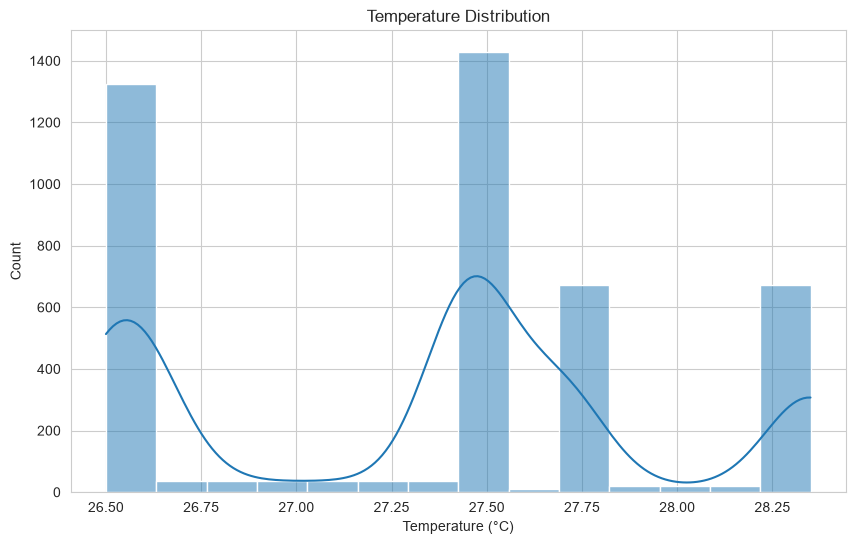

In [15]:
sns.histplot(model_df["Temperature (°C)"], kde=True)
plt.title("Temperature Distribution")
plt.show()

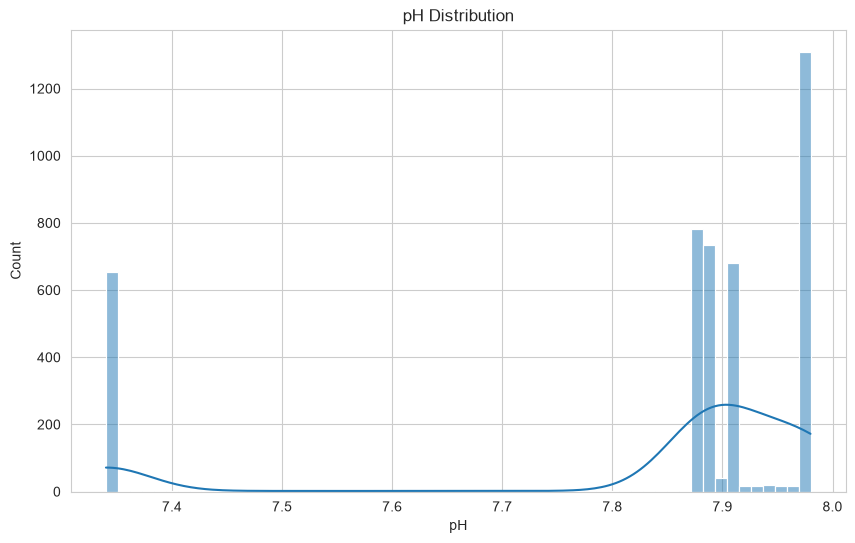

In [16]:
sns.histplot(model_df["pH"], kde=True)
plt.title("pH Distribution")
plt.show()

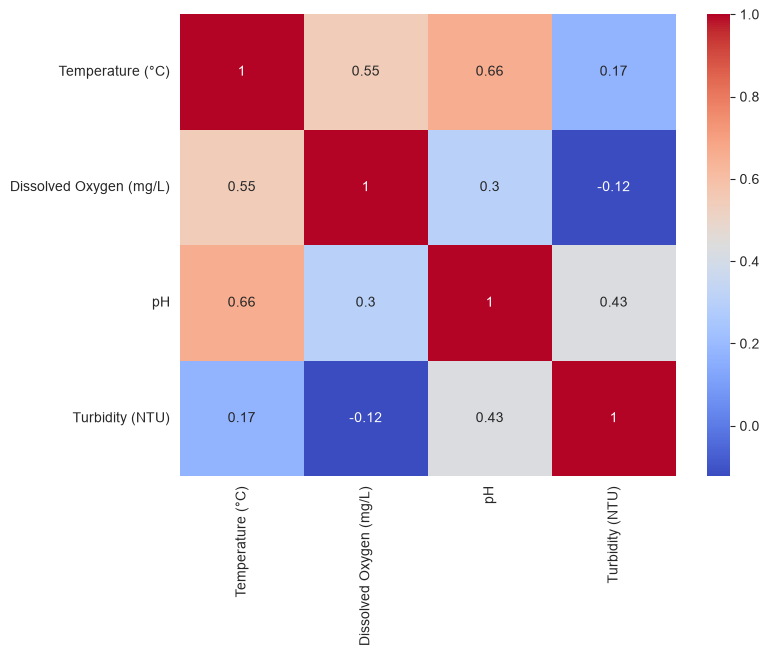

In [17]:
numeric_df = model_df.select_dtypes(include=np.number)

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

In [18]:
X = model_df[
    [
        "Temperature (°C)",
        "Dissolved Oxygen (mg/L)",
        "pH",
        "Turbidity (NTU)"
    ]
]

y = model_df["Health Status"]

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [21]:
df["Health Status"].value_counts()

Health Status
Stable     3678
At Risk     705
Name: count, dtype: int64

In [22]:
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [23]:
X = model_df[
    [
        "Temperature (°C)",
        "Dissolved Oxygen (mg/L)",
        "pH",
        "Turbidity (NTU)"
    ]
]

y = model_df["Health Status"]

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [25]:
print(X_train.shape)
print(X_test.shape)

(3506, 4)
(877, 4)


In [26]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [27]:
predictions = model.predict(X_test)

In [28]:
accuracy = accuracy_score(
    y_test,
    predictions
)

print("Accuracy:", accuracy)

Accuracy: 0.9988597491448119


In [29]:
print(
    classification_report(
        y_test,
        predictions
    )
)

              precision    recall  f1-score   support

     At Risk       0.99      1.00      1.00       138
      Stable       1.00      1.00      1.00       739

    accuracy                           1.00       877
   macro avg       1.00      1.00      1.00       877
weighted avg       1.00      1.00      1.00       877



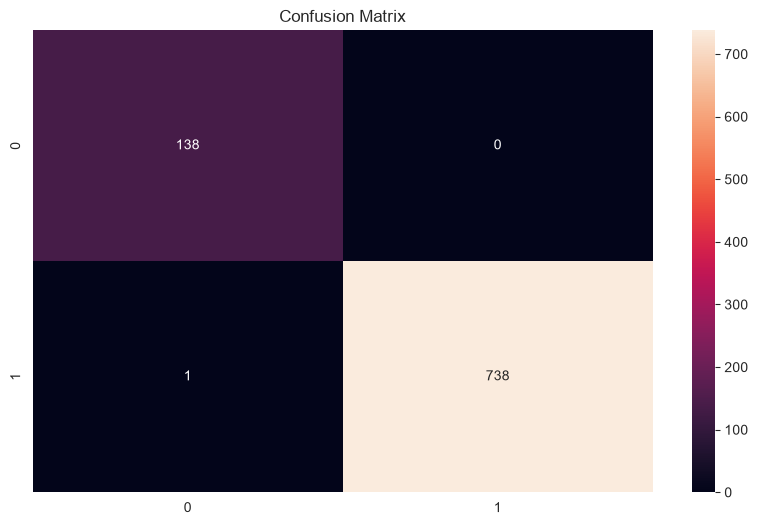

In [30]:
cm = confusion_matrix(
    y_test,
    predictions
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix")
plt.show()

In [31]:
classification_report(y_test, predictions)

'              precision    recall  f1-score   support\n\n     At Risk       0.99      1.00      1.00       138\n      Stable       1.00      1.00      1.00       739\n\n    accuracy                           1.00       877\n   macro avg       1.00      1.00      1.00       877\nweighted avg       1.00      1.00      1.00       877\n'

In [32]:
print(X.columns)

Index(['Temperature (°C)', 'Dissolved Oxygen (mg/L)', 'pH', 'Turbidity (NTU)'], dtype='str')


In [33]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
0,Temperature (°C),0.602149
1,Dissolved Oxygen (mg/L),0.348248
2,pH,0.048268
3,Turbidity (NTU),0.001334


In [34]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
0,Temperature (°C),0.602149
1,Dissolved Oxygen (mg/L),0.348248
2,pH,0.048268
3,Turbidity (NTU),0.001334


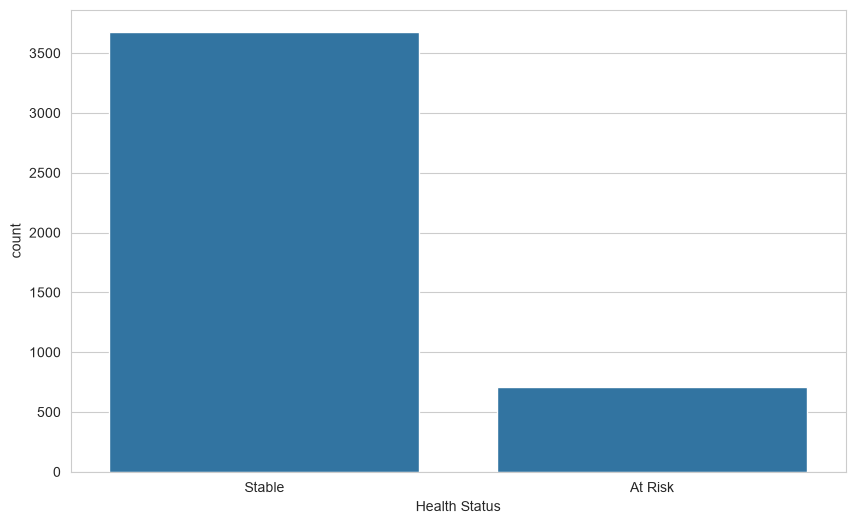

In [35]:
sns.countplot(x="Health Status", data=model_df)
plt.show()

In [36]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model,
    X,
    y,
    cv=5
)

print(scores)
print(scores.mean())

[1.         0.97377423 1.         1.         0.98858447]
0.9924717410433036


In [37]:
import joblib

joblib.dump(model, "water_health_model.pkl")

['water_health_model.pkl']

In [38]:
sample = [[30, 4.5, 6.8, 18]]

prediction = model.predict(sample)

print(prediction)

['At Risk']


c:\Users\ddhar\waterdiseaseproj\wenv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [40]:
import os

print(os.listdir())

['Data_Model_IoTMLCQ_2024.xlsx', 'eda1.ipynb', 'water_health_model.pkl', 'wenv']
